# Smart MCQ Solver
### NLP-Based Multiple-Choice Question Ranking

## 1. Project Overview

Smart MCQ Solver treats each multiple-choice question as a ranking problem.
Given one prompt and five candidate answers, the system scores the
question-option pairs and returns the three highest-ranked options. This
notebook preserves the existing project work while organizing its
preprocessing, engineered features, classical models, pretrained semantic
baseline, validation, experiment tracking, ensemble experiments, and Kaggle
evaluation into one reproducible workflow.

The code-backed final pipeline uses feature-based ranking models, a
question-level classifier, engineered heuristic signals, and Rank SGD. W&B
is used for experiment tracking, and Kaggle provides the external
evaluation records documented later in the notebook.

## Project Pipeline

1. Project Overview
2. Dataset Loading
3. Exploratory Data Analysis
4. Text Preprocessing
5. Feature Engineering
6. Feature Selection
7. Model Development
8. GroupKFold Validation
9. W&B Experiment Tracking
10. Ensemble Development
11. Kaggle Evaluation
12. Final Model Selection
13. Project Summary
14. Conclusion and Future Work
        


## Execution Notes and W&B Setup

Run the notebook from top to bottom in a Kaggle Notebook with the Smart MCQ Solver competition data available. The code is intentionally left without stored execution outputs so the results are generated in the execution environment.

### W&B authentication

Before running the W&B section, create a Kaggle Secret named `WANDB_API_KEY` containing your Weights & Biases API key. In Kaggle, use **Add-ons → Secrets → Add a new secret**, enter `WANDB_API_KEY` as the label, and paste the API key as the value. Then enable the secret for this notebook if Kaggle presents that option.

**Do not paste the API key into any notebook cell or commit it to GitHub.** The W&B cell below reads it through `UserSecretsClient()` and falls back to the `WANDB_API_KEY` environment variable.

If the W&B package is unavailable in the execution environment, install it in a separate setup cell before the W&B section. The notebook does not contain or expose a secret value.
        

In [32]:
import math
import re
import unicodedata
import warnings

from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MaxAbsScaler

warnings.filterwarnings("ignore")

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
OPTION_COLS = ["A", "B", "C", "D", "E"]
TARGET_COL = "answer"
NEGATION_WORDS = {"no", "not", "never", "none", "cannot", "can't", "except", "incorrect", "false", "least"}

## 2. Dataset Loading

The competition files are loaded from the Kaggle input directory. The sample
submission is retained so every generated prediction is written with the
required IDs and submission format.
        

In [33]:
import pandas as pd

sample = pd.read_csv('/kaggle/input/datasets/vishwapatel4951/smart-mcq-solver/sample_submission.csv')

train = pd.read_csv('/kaggle/input/datasets/vishwapatel4951/smart-mcq-solver/train.csv')
test = pd.read_csv('/kaggle/input/datasets/vishwapatel4951/smart-mcq-solver/test.csv')

print("Train Shape:", train.shape)
print("Test Shape:", test.shape)

train.head()

Train Shape: (2000, 8)
Test Shape: (500, 7)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.,Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the p...,"Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, ...",Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is ...,Martin Heidegger believes that the relationship between time and human existence is cyclical. The past and present are interconnected and the future is pred...,"Martin Heidegger believes that time is an illusion, and the past, present, and future are all happening simultaneously. Humans exist outside of this illusio...",B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion...,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion...,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion...,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion...,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fissio...,A
2,3,Determine the correct option: What is the term used in astrophysics to describe light-matter interactions resulting in energy shifts in the radiation field?...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Martin Heidegger's view on the relationship between time and human existence? carefully.,Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the p...,"Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, ...",Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is ...,Martin Heidegger believes that the relationship between time and human existence is cyclical. The past and present are interconnected and the future is pred...,"Martin Heidegger believes that time is an illusion, and the past, present, and future are all happening simultaneously. Humans exist outside of this illusio...",B
4,5,"Identify the correct statement: What is the concept of simultaneity in Einstein's book, Relativity? carefully.","Simultaneity is relative, meaning that two events that appear simultaneous to an observer in a particular inertial reference frame need not be judged as sim...","Simultaneity is relative, meaning that two events that appear simultaneous to an observer in a particular inertial reference frame will always be judged as ...","Simultaneity is absolute, meaning that two events that appear simultaneous to an observer in a particular inertial reference frame will always be judged as ...",Simultaneity is a concept that applies only to Newtonian theories and not to relativistic theories.,Simultaneity is a concept that applies only to relativistic theories and not to Newtonian theories.,A


## 3. Exploratory Data Analysis

The first inspection checks dimensions, schema, answer-label balance, text
lengths, and missing values. These checks establish the shape of the ranking
task and identify data-quality issues before text transformation.

### Dataset Dimensions and Schema
        

In [34]:
print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("Columns    :", train.columns.tolist())

display(train.head(3))
display(test.head(3))

Train shape: (2000, 8)
Test shape : (500, 7)
Columns    : ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.,Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the p...,"Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, ...",Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is ...,Martin Heidegger believes that the relationship between time and human existence is cyclical. The past and present are interconnected and the future is pred...,"Martin Heidegger believes that time is an illusion, and the past, present, and future are all happening simultaneously. Humans exist outside of this illusio...",B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion...,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion...,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion...,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion...,Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fissio...,A
2,3,Determine the correct option: What is the term used in astrophysics to describe light-matter interactions resulting in energy shifts in the radiation field?...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C


,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the relationship between the Hamiltonians and eigenstates in supersymmetric quantum mechanics? carefully.,"For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with the same energy.","For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with a higher energy.","For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with a different spin.","For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with a different energy.","For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with a lower energy."
1,2,"What is the estimated redshift of CEERS-93316, a candidate high-redshift galaxy observed by the James Webb Space Telescope?","Approximately z = 6.0, corresponding to 1 billion years after the Big Bang.","Approximately z = 16.7, corresponding to 235.8 million years after the Big Bang.","Approximately z = 3.0, corresponding to 5 billion years after the Big Bang.","Approximately z = 10.0, corresponding to 13 billion years after the Big Bang.","Approximately z = 13.0, corresponding to 30 billion light-years away from Earth."
2,3,Pick the best possible answer: What is the reason for the sun appearing slightly yellowish when viewed from Earth? from the following choices.,The sun appears yellowish due to a reflection of the Earth's atmosphere.,"The longer wavelengths of light, such as red and yellow, are not scattered away and are directly visible when looking towards the sun.","The sun appears yellowish due to the scattering of all colors of light, mainly blue and green, in the Earth's atmosphere.","The sun emits a yellow light due to its own spectrum, which is visible when viewed from Earth.","The atmosphere absorbs the shorter wavelengths of light, such as blue and red, leaving only the longer wavelengths of light, such as green and yellow, visib..."


### Target Distribution and Text Lengths

The answer distribution and text-length plots help reveal class imbalance and the amount of text available to the models.

,count
answer,
A,369
B,490
C,459
D,358
E,324


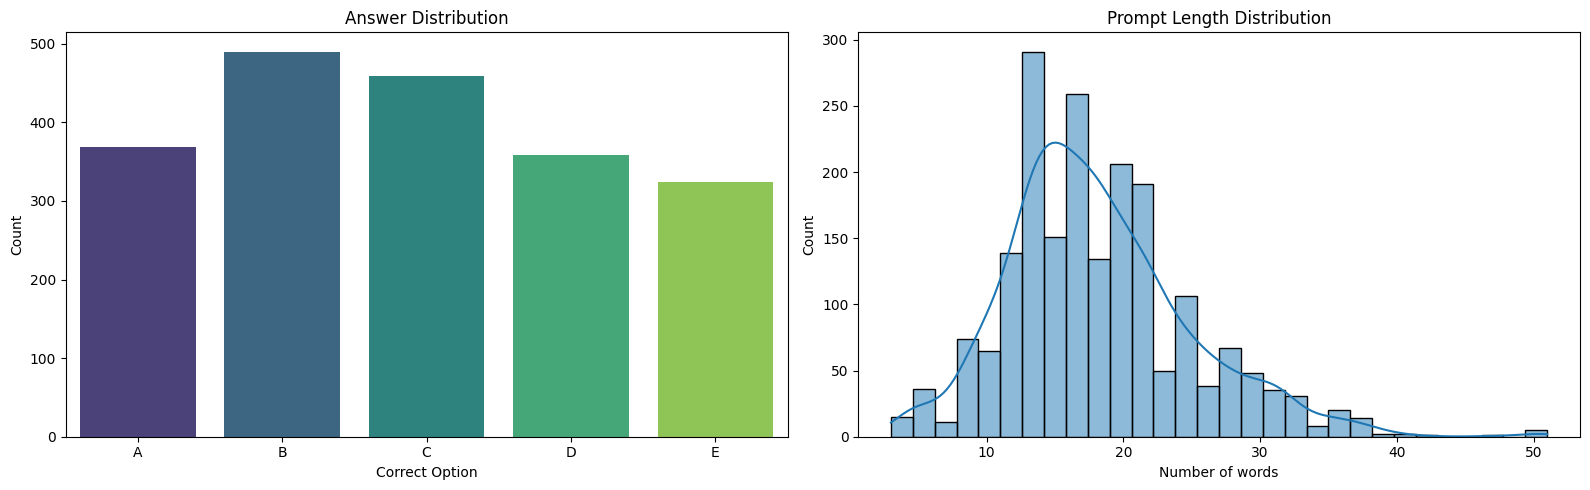

,prompt_words,option_words_mean,option_words_max
count,2000.00000,2000.000000,2000.00000
mean,18.14650,26.279600,30.51900
std,6.78189,17.029056,19.02216
min,3.00000,1.000000,1.00000
25%,14.00000,14.600000,17.00000
50%,17.00000,23.000000,28.00000
75%,22.00000,36.800000,42.00000
max,51.00000,85.400000,118.00000


In [35]:
answer_distribution = train[TARGET_COL].value_counts().sort_index()
display(answer_distribution.rename("count").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    x=answer_distribution.index,
    y=answer_distribution.values,
    palette="viridis",
    ax=axes[0]
)
axes[0].set_title("Answer Distribution")
axes[0].set_xlabel("Correct Option")
axes[0].set_ylabel("Count")

prompt_lengths = train["prompt"].str.split().map(len)
option_lengths = pd.concat(
    [train[col].str.split().map(len).rename(col) for col in OPTION_COLS],
    axis=1
)

sns.histplot(prompt_lengths, bins=30, kde=True, ax=axes[1], color="#1f77b4")
axes[1].set_title("Prompt Length Distribution")
axes[1].set_xlabel("Number of words")

plt.tight_layout()
plt.show()

length_summary = pd.DataFrame({
    "prompt_words": prompt_lengths.describe(),
    "option_words_mean": option_lengths.mean(axis=1).describe(),
    "option_words_max": option_lengths.max(axis=1).describe()
})
display(length_summary)

### Missing Values

Missing-value counts are checked for both train and test so the preprocessing functions do not silently receive unexpected nulls.

In [36]:
train_nulls = train.isna().sum().rename("missing_count").to_frame()
test_nulls = test.isna().sum().rename("missing_count").to_frame()

print("Missing values in train:")
display(train_nulls)
print("Missing values in test:")
display(test_nulls)

Missing values in train:


,missing_count
id,0
prompt,0
A,0
B,0
C,0
D,0
E,0
answer,0


Missing values in test:


,missing_count
id,0
prompt,0
A,0
B,0
C,0
D,0
E,0


## 4. Text Preprocessing

The shared `normalize_text` function applies the operations actually used by
the project: Unicode NFKD normalization, ASCII conversion, lowercasing,
replacement of non-alphanumeric characters with spaces, and whitespace
normalization. Prompts and all five options pass through the same function,
after which token and bigram helpers support feature construction.
        

In [37]:
def normalize_text(text):
    text = str(text)
    text = unicodedata.normalize("NFKD", text)
    text = text.encode("ascii", "ignore").decode("utf-8", errors="ignore")
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize(text):
    return [token for token in normalize_text(text).split() if token]


def bigrams(tokens):
    return set(zip(tokens, tokens[1:])) if len(tokens) >= 2 else set()


def safe_div(numerator, denominator):
    return numerator / denominator if denominator else 0.0


def has_negation(tokens):
    return int(any(token in NEGATION_WORDS for token in tokens))


def extract_numbers(text):
    return re.findall(r"\d+", str(text))


def prepare_base_frame(df):
    prepared = df.copy()
    prepared["prompt_clean"] = prepared["prompt"].map(normalize_text)

    for col in OPTION_COLS:
        prepared[f"{col}_clean"] = prepared[col].map(normalize_text)

    prepared["all_choices_text"] = prepared.apply(
        lambda row: " ".join([f"{col} {row[f'{col}_clean']}" for col in OPTION_COLS]),
        axis=1
    )

    prepared["question_bundle"] = prepared.apply(
        lambda row: (
            f"prompt {row['prompt_clean']} "
            + " ".join([f"choice {col} {row[f'{col}_clean']}" for col in OPTION_COLS])
        ),
        axis=1
    )
    return prepared


train_prepared = prepare_base_frame(train)
test_prepared = prepare_base_frame(test)

display(train_prepared[["id", "prompt_clean", "A_clean", "B_clean", "C_clean", "D_clean", "E_clean"]].head(2))

,id,prompt_clean,A_clean,B_clean,C_clean,D_clean,E_clean
0,1,pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options,martin heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end the relationship to the pa...,martin heidegger believes that humans do not exist inside time but that they are time the relationship to the past is a present awareness of having been and...,martin heidegger does not believe in the existence of time or that it has any effect on human consciousness the relationship to the past and the future is i...,martin heidegger believes that the relationship between time and human existence is cyclical the past and present are interconnected and the future is prede...,martin heidegger believes that time is an illusion and the past present and future are all happening simultaneously humans exist outside of this illusion an...
1,2,what is accelerator based light ion fusion,accelerator based light ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light ion fusion...,accelerator based light ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy ion fusion...,accelerator based light ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light ion fusion...,accelerator based light ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy ion fusion...,accelerator based light ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light ion fissio...


## 5. Feature Engineering

Each question-option pair becomes one candidate-level training row. The
feature builder combines the cleaned prompt and option text with lexical
overlap, Jaccard similarity, prompt/option coverage, IDF-weighted overlap,
number consistency, negation indicators, bigram overlap, token uniqueness
relative to the other options, and relative option length.

This representation converts the original MCQ into a ranking dataset: each
candidate receives a set of features and a binary target indicating whether
it is the correct option. The IDF lookup is built from the prepared train and
test text exactly as in the existing implementation.
        

In [38]:
def build_idf_lookup(prepared_frames):
    document_frequency = Counter()
    total_documents = 0

    for frame in prepared_frames:
        prompt_sets = frame["prompt_clean"].map(lambda text: set(text.split()))
        total_documents += len(prompt_sets)
        for token_set in prompt_sets:
            document_frequency.update(token_set)

        for col in OPTION_COLS:
            option_sets = frame[f"{col}_clean"].map(lambda text: set(text.split()))
            total_documents += len(option_sets)
            for token_set in option_sets:
                document_frequency.update(token_set)

    idf_lookup = {
        token: math.log((1 + total_documents) / (1 + freq)) + 1.0
        for token, freq in document_frequency.items()
    }
    return idf_lookup


idf_lookup = build_idf_lookup([train_prepared, test_prepared])
print("Unique tokens with IDF weights:", len(idf_lookup))

Unique tokens with IDF weights: 2991


In [39]:
def build_candidate_frame(df, include_target=True):
    records = []

    for row in df.itertuples(index=False):
        prompt_clean = row.prompt_clean
        prompt_tokens = tokenize(prompt_clean)
        prompt_token_set = set(prompt_tokens)
        prompt_bigrams = bigrams(prompt_tokens)
        prompt_numbers = set(extract_numbers(prompt_clean))
        prompt_negation = has_negation(prompt_tokens)

        option_texts = {col: getattr(row, f"{col}_clean") for col in OPTION_COLS}
        option_tokens_map = {col: tokenize(text) for col, text in option_texts.items()}
        option_sets_map = {col: set(tokens) for col, tokens in option_tokens_map.items()}
        option_bigrams_map = {col: bigrams(tokens) for col, tokens in option_tokens_map.items()}
        option_numbers_map = {col: set(extract_numbers(option_texts[col])) for col in OPTION_COLS}

        option_lengths = {col: len(option_tokens_map[col]) for col in OPTION_COLS}
        avg_option_length = np.mean(list(option_lengths.values()))
        max_option_length = max(option_lengths.values())
        min_option_length = min(option_lengths.values())

        for option_idx, option in enumerate(OPTION_COLS):
            option_clean = option_texts[option]
            option_tokens = option_tokens_map[option]
            option_token_set = option_sets_map[option]
            option_bigrams = option_bigrams_map[option]
            option_numbers = option_numbers_map[option]

            shared_tokens = prompt_token_set & option_token_set
            union_tokens = prompt_token_set | option_token_set
            shared_bigrams = prompt_bigrams & option_bigrams
            weighted_overlap = sum(idf_lookup.get(token, 1.0) for token in shared_tokens)
            rare_overlap_count = sum(1 for token in shared_tokens if idf_lookup.get(token, 1.0) > 4.0)

            other_options = [col for col in OPTION_COLS if col != option]
            other_sets = [option_sets_map[col] for col in other_options]
            other_unions = set().union(*other_sets) if other_sets else set()
            unique_vs_others = option_token_set - other_unions
            shared_with_others = [
                len(option_token_set & option_sets_map[col]) for col in other_options
            ]

            record = {
                "question_id": row.id,
                "option": option,
                "pair_text": f"{prompt_clean} [sep] option {option} [sep] {option_clean}",
                "question_bundle": row.question_bundle,
                "option_text": option_clean,
                "prompt_word_count": len(prompt_tokens),
                "option_word_count": len(option_tokens),
                "overlap_count": len(shared_tokens),
                "jaccard_overlap": safe_div(len(shared_tokens), len(union_tokens)),
                "prompt_coverage": safe_div(len(shared_tokens), len(prompt_token_set)),
                "option_coverage": safe_div(len(shared_tokens), len(option_token_set)),
                "weighted_overlap": weighted_overlap,
                "rare_overlap_count": rare_overlap_count,
                "bigram_overlap_count": len(shared_bigrams),
                "number_overlap_count": len(prompt_numbers & option_numbers),
                "number_mismatch_flag": int(bool(prompt_numbers) and not bool(prompt_numbers & option_numbers)),
                "prompt_has_negation": prompt_negation,
                "option_has_negation": has_negation(option_tokens),
                "negation_match": int(prompt_negation == has_negation(option_tokens)),
                "token_uniqueness_vs_others": len(unique_vs_others),
                "shared_with_others_mean": float(np.mean(shared_with_others)) if shared_with_others else 0.0,
                "shared_with_others_max": float(np.max(shared_with_others)) if shared_with_others else 0.0,
                "relative_option_length": safe_div(len(option_tokens), avg_option_length),
                "is_longest_option": int(option_lengths[option] == max_option_length),
                "is_shortest_option": int(option_lengths[option] == min_option_length),
                "option_index": option_idx,
            }

            if include_target:
                record["target"] = int(getattr(row, TARGET_COL) == option)

            records.append(record)

    return pd.DataFrame(records)


train_long = build_candidate_frame(train_prepared, include_target=True)
test_long = build_candidate_frame(test_prepared, include_target=False)

print("Candidate train shape:", train_long.shape)
print("Candidate test shape :", test_long.shape)
display(train_long.head(10))

Candidate train shape: (10000, 27)
Candidate test shape : (2500, 26)


,question_id,option,pair_text,question_bundle,option_text,prompt_word_count,option_word_count,overlap_count,jaccard_overlap,prompt_coverage,option_coverage,weighted_overlap,rare_overlap_count,bigram_overlap_count,number_overlap_count,number_mismatch_flag,prompt_has_negation,option_has_negation,negation_match,token_uniqueness_vs_others,shared_with_others_mean,shared_with_others_max,relative_option_length,is_longest_option,is_shortest_option,option_index,target
0,1,A,pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options [sep] option A [...,prompt pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options choice A ...,martin heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end the relationship to the pa...,23,52,8,0.153846,0.380952,0.205128,29.000972,3,2,0,0,0,1,0,17,15.00,18.0,1.347150,1,0,0,0
1,1,B,pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options [sep] option B [...,prompt pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options choice A ...,martin heidegger believes that humans do not exist inside time but that they are time the relationship to the past is a present awareness of having been and...,23,41,7,0.148936,0.333333,0.212121,25.610582,3,2,0,0,0,1,0,11,16.00,18.0,1.062176,0,0,1,1
2,1,C,pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options [sep] option C [...,prompt pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options choice A ...,martin heidegger does not believe in the existence of time or that it has any effect on human consciousness the relationship to the past and the future is i...,23,38,10,0.250000,0.476190,0.344828,41.146406,5,5,0,0,0,1,0,10,13.75,15.0,0.984456,0,0,2,0
3,1,D,pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options [sep] option D [...,prompt pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options choice A ...,martin heidegger believes that the relationship between time and human existence is cyclical the past and present are interconnected and the future is prede...,23,31,10,0.277778,0.476190,0.400000,41.745596,5,7,0,0,0,1,0,6,13.75,15.0,0.803109,0,1,3,0
4,1,E,pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options [sep] option E [...,prompt pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options choice A ...,martin heidegger believes that time is an illusion and the past present and future are all happening simultaneously humans exist outside of this illusion an...,23,31,6,0.142857,0.285714,0.222222,20.947953,2,1,0,0,0,0,1,11,13.00,16.0,0.803109,0,1,4,0
5,2,A,what is accelerator based light ion fusion [sep] option A [sep] accelerator based light ion fusion is a technique that uses particle accelerators to achieve...,prompt what is accelerator based light ion fusion choice A accelerator based light ion fusion is a technique that uses particle accelerators to achieve part...,accelerator based light ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light ion fusion...,7,66,6,0.117647,0.857143,0.120000,27.584328,3,4,0,0,0,0,1,0,43.00,50.0,1.071429,1,0,0,1
6,2,B,what is accelerator based light ion fusion [sep] option B [sep] accelerator

### Feature Preview

The following table is a small diagnostic view of the engineered heuristic
signals by option. It is retained as an inspection aid rather than treated as
a model result.
        

In [40]:
heuristic_preview = (
    train_long.groupby("option")[["weighted_overlap", "jaccard_overlap", "token_uniqueness_vs_others"]]
    .mean()
    .round(3)
)
display(heuristic_preview)

,weighted_overlap,jaccard_overlap,token_uniqueness_vs_others
option,,,
A,18.665,0.161,3.124
B,18.420,0.159,2.942
C,18.949,0.160,3.342
D,18.562,0.159,3.036
E,18.179,0.156,3.092


## 6. Feature Selection

The model pipelines apply chi-square `SelectPercentile` after their text and
numeric feature transformers. The selected features are passed directly to
the downstream classifiers; the percentile is model-specific and remains
unchanged from the original implementation.
        

In [41]:
numeric_features = [
    "prompt_word_count",
    "option_word_count",
    "overlap_count",
    "jaccard_overlap",
    "prompt_coverage",
    "option_coverage",
    "weighted_overlap",
    "rare_overlap_count",
    "bigram_overlap_count",
    "number_overlap_count",
    "number_mismatch_flag",
    "prompt_has_negation",
    "option_has_negation",
    "negation_match",
    "token_uniqueness_vs_others",
    "shared_with_others_mean",
    "shared_with_others_max",
    "relative_option_length",
    "is_longest_option",
    "is_shortest_option",
    "option_index",
]


rank_feature_columns = ["pair_text", "question_bundle", "option_text"] + numeric_features
question_feature_column = "question_bundle"


def build_rank_logreg_pipeline():
    feature_builder = ColumnTransformer(
        transformers=[
            (
                "pair_word_tfidf",
                TfidfVectorizer(
                    strip_accents="unicode",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.97,
                    sublinear_tf=True
                ),
                "pair_text",
            ),
            (
                "pair_char_tfidf",
                TfidfVectorizer(
                    analyzer="char_wb",
                    ngram_range=(3, 5),
                    min_df=2,
                    sublinear_tf=True
                ),
                "pair_text",
            ),
            (
                "option_word_tfidf",
                TfidfVectorizer(
                    strip_accents="unicode",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.98,
                    sublinear_tf=True
                ),
                "option_text",
            ),
            (
                "numeric",
                MaxAbsScaler(),
                numeric_features,
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )

    return Pipeline(
        steps=[
            ("features", feature_builder),
            ("select", SelectPercentile(score_func=chi2, percentile=55)),
            (
                "classifier",
                LogisticRegression(
                    C=2.5,
                    class_weight="balanced",
                    max_iter=3000,
                    solver="liblinear",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


def build_rank_nb_pipeline():
    feature_builder = ColumnTransformer(
        transformers=[
            (
                "pair_word_tfidf",
                TfidfVectorizer(
                    strip_accents="unicode",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.98,
                    sublinear_tf=True
                ),
                "pair_text",
            ),
            (
                "question_word_tfidf",
                TfidfVectorizer(
                    strip_accents="unicode",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.98,
                    sublinear_tf=True
                ),
                "question_bundle",
            ),
            (
                "numeric",
                MaxAbsScaler(),
                numeric_features,
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )

    return Pipeline(
        steps=[
            ("features", feature_builder),
            ("select", SelectPercentile(score_func=chi2, percentile=40)),
            ("classifier", ComplementNB(alpha=0.35)),
        ]
    )


def build_question_multiclass_pipeline():
    return Pipeline(
        steps=[
            (
                "features",
                ColumnTransformer(
                    transformers=[
                        (
                            "bundle_word_tfidf",
                            TfidfVectorizer(
                                strip_accents="unicode",
                                ngram_range=(1, 3),
                                min_df=2,
                                max_df=0.97,
                                sublinear_tf=True
                            ),
                            "question_bundle",
                        ),
                        (
                            "bundle_char_tfidf",
                            TfidfVectorizer(
                                analyzer="char_wb",
                                ngram_range=(3, 5),
                                min_df=2,
                                sublinear_tf=True
                            ),
                            "question_bundle",
                        ),
                    ],
                    remainder="drop",
                    sparse_threshold=1.0,
                ),
            ),
            ("select", SelectPercentile(score_func=chi2, percentile=65)),
            (
                "classifier",
                LogisticRegression(
                    C=3.0,
                    class_weight="balanced",
                    max_iter=4000,
                    solver="liblinear",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

## 7. Model Development

The project explores several complementary approaches:

- **Feature-based logistic ranking:** a classical supervised model over
  TF-IDF and engineered candidate-level features.
- **Complement Naive Bayes:** a classical text-classification baseline.
- **Question-level TF-IDF classifier:** predicts the answer label from the
  complete question bundle.
- **Rank SGD:** an additional linear ranking model using stochastic gradient
  descent.
- **Question SVD + Logistic Regression:** an additional latent semantic
  question-level model.
- **Pretrained all-MiniLM-L6-v2:** a standalone semantic-similarity baseline
  evaluated later.

The first five approaches are implemented in the notebook's model pipelines.
The MiniLM encoder is pretrained and is not claimed to be part of the final
ensemble unless a blend explicitly uses its predictions; the final v4 blend
does not.
        

In [42]:
label_to_idx = {label: idx for idx, label in enumerate(OPTION_COLS)}
idx_to_label = {idx: label for label, idx in label_to_idx.items()}

question_train = train_prepared[["id", "question_bundle", "answer"]].copy()
question_test = test_prepared[["id", "question_bundle"]].copy()
question_train["label_idx"] = question_train["answer"].map(label_to_idx)


def apk(actual, predicted, k=3):
    predicted = predicted[:k]
    score = 0.0
    num_hits = 0.0

    for i, pred in enumerate(predicted):
        if pred == actual and pred not in predicted[:i]:
            num_hits += 1.0
            score += num_hits / (i + 1.0)

    return score


def mapk(actual_labels, predicted_labels, k=3):
    return np.mean([apk(a, p, k=k) for a, p in zip(actual_labels, predicted_labels)])


def minmax_normalize_by_question(df, score_columns):
    normalized = df.copy()
    for score_column in score_columns:
        group_min = normalized.groupby("question_id")[score_column].transform("min")
        group_max = normalized.groupby("question_id")[score_column].transform("max")
        normalized[f"{score_column}_norm"] = np.where(
            (group_max - group_min) > 0,
            (normalized[score_column] - group_min) / (group_max - group_min),
            0.0
        )
    return normalized


def build_question_probability_frame(question_ids, probability_matrix):
    rows = []
    for qid, probs in zip(question_ids, probability_matrix):
        for option_idx, option in enumerate(OPTION_COLS):
            rows.append({
                "question_id": qid,
                "option": option,
                "question_prob": probs[option_idx]
            })
    return pd.DataFrame(rows)


def topk_predictions(score_frame, score_column="blend_score", k=3):
    ranked = (
        score_frame.sort_values(["question_id", score_column], ascending=[True, False])
        .groupby("question_id")["option"]
        .apply(lambda values: list(values.iloc[:k]))
    )
    return ranked


feature_columns = rank_feature_columns
groups = train_long["question_id"].values
group_kfold = GroupKFold(n_splits=5)
answer_lookup = train.set_index("id")["answer"].to_dict()

fold_scores = []

for fold, (train_idx, valid_idx) in enumerate(group_kfold.split(train_long, train_long["target"], groups=groups), start=1):
    train_fold = train_long.iloc[train_idx].copy()
    valid_fold = train_long.iloc[valid_idx].copy()

    train_question_ids = sorted(train_fold["question_id"].unique())
    valid_question_ids = sorted(valid_fold["question_id"].unique())

    question_train_fold = question_train[question_train["id"].isin(train_question_ids)].copy()
    question_valid_fold = question_train[question_train["id"].isin(valid_question_ids)].copy()

    rank_logreg = build_rank_logreg_pipeline()
    rank_logreg.fit(train_fold[feature_columns], train_fold["target"])
    logreg_positive_index = list(rank_logreg.classes_).index(1)
    valid_fold["rank_logreg_score"] = rank_logreg.predict_proba(valid_fold[feature_columns])[:, logreg_positive_index]

    rank_nb = build_rank_nb_pipeline()
    rank_nb.fit(train_fold[feature_columns], train_fold["target"])
    nb_positive_index = list(rank_nb.classes_).index(1)
    valid_fold["rank_nb_score"] = rank_nb.predict_proba(valid_fold[feature_columns])[:, nb_positive_index]

    question_model = build_question_multiclass_pipeline()
    question_model.fit(question_train_fold[[question_feature_column]], question_train_fold["label_idx"])
    valid_question_probs = question_model.predict_proba(question_valid_fold[[question_feature_column]])
    valid_question_prob_frame = build_question_probability_frame(
        question_valid_fold["id"].tolist(),
        valid_question_probs
    )

    valid_fold = valid_fold.merge(valid_question_prob_frame, on=["question_id", "option"], how="left")
    valid_fold["heuristic_score"] = (
        0.40 * valid_fold["weighted_overlap"]
        + 0.20 * valid_fold["prompt_coverage"]
        + 0.10 * valid_fold["option_coverage"]
        + 0.15 * valid_fold["bigram_overlap_count"]
        + 0.15 * valid_fold["token_uniqueness_vs_others"]
    )

    valid_fold = minmax_normalize_by_question(
        valid_fold,
        ["rank_logreg_score", "rank_nb_score", "question_prob", "heuristic_score"]
    )

    valid_fold["blend_score"] = (
        0.36 * valid_fold["rank_logreg_score_norm"]
        + 0.22 * valid_fold["rank_nb_score_norm"]
        + 0.30 * valid_fold["question_prob_norm"]
        + 0.12 * valid_fold["heuristic_score_norm"]
    )

    ranked_predictions = topk_predictions(valid_fold, score_column="blend_score", k=3)
    actual_labels = [answer_lookup[qid] for qid in ranked_predictions.index.tolist()]
    predicted_labels = ranked_predictions.tolist()
    fold_map3 = mapk(actual_labels, predicted_labels, k=3)
    fold_scores.append(fold_map3)

    print(f"Fold {fold} MAP@3: {fold_map3:.5f}")

print("\nCross-validation MAP@3 scores:", [round(float(score), 5) for score in fold_scores])
print("Mean CV MAP@3:", round(float(np.mean(fold_scores)), 5))
print("Std  CV MAP@3:", round(float(np.std(fold_scores)), 5))

Fold 1 MAP@3: 0.99750
Fold 2 MAP@3: 1.00000
Fold 3 MAP@3: 0.99250
Fold 4 MAP@3: 1.00000
Fold 5 MAP@3: 0.99750

Cross-validation MAP@3 scores: [0.9975, 1.0, 0.9925, 1.0, 0.9975]
Mean CV MAP@3: 0.9975
Std  CV MAP@3: 0.00274


## 8. GroupKFold Validation

Question-level grouping is required because each question expands into five
candidate rows. `GroupKFold(n_splits=5)` keeps all five options from a
question in the same fold, preventing candidate rows from the same question
from appearing in both training and validation. The first validation block
evaluates the original three-signal ensemble with MAP@3.
        

### Additional Model Pipelines

These two pipelines were added as complementary experiments before the extended ensemble comparison.

In [43]:
# ---- Model 4: rank-level SGD classifier (different algorithm family from the logistic model) ----
def build_rank_sgd_pipeline():
    feature_builder = ColumnTransformer(
        transformers=[
            (
                "pair_word_tfidf",
                TfidfVectorizer(
                    strip_accents="unicode",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.97,
                    sublinear_tf=True,
                ),
                "pair_text",
            ),
            (
                "option_word_tfidf",
                TfidfVectorizer(
                    strip_accents="unicode",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.98,
                    sublinear_tf=True,
                ),
                "option_text",
            ),
            ("numeric", MaxAbsScaler(), numeric_features),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )

    return Pipeline(
        steps=[
            ("features", feature_builder),
            ("select", SelectPercentile(score_func=chi2, percentile=50)),
            (
                "classifier",
                SGDClassifier(
                    loss="modified_huber",
                    alpha=1e-4,
                    class_weight="balanced",
                    max_iter=2000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


# ---- Model 5: question-level latent semantic model (TF-IDF -> SVD -> Logistic Regression) ----
from sklearn.decomposition import TruncatedSVD


def build_question_svd_pipeline():
    return Pipeline(
        steps=[
            (
                "tfidf",
                TfidfVectorizer(
                    strip_accents="unicode",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.97,
                    sublinear_tf=True,
                ),
            ),
            ("svd", TruncatedSVD(n_components=120, random_state=RANDOM_STATE)),
            (
                "classifier",
                LogisticRegression(
                    C=4.0,
                    class_weight="balanced",
                    max_iter=4000,
                    solver="lbfgs",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


print("Model 4 (rank_sgd) and Model 5 (question_svd) pipelines defined.")

Model 4 (rank_sgd) and Model 5 (question_svd) pipelines defined.


### Extended Ensemble Cross-Validation

The next block compares the original three-signal blend with the five-model blend using the same grouped folds.

In [44]:
cv_scores_old, cv_scores_new = [], []

for fold, (train_idx, valid_idx) in enumerate(
    group_kfold.split(train_long, train_long["target"], groups=groups), start=1
):
    train_fold = train_long.iloc[train_idx].copy()
    valid_fold = train_long.iloc[valid_idx].copy()

    train_question_ids = sorted(train_fold["question_id"].unique())
    valid_question_ids = sorted(valid_fold["question_id"].unique())

    question_train_fold = question_train[
        question_train["id"].isin(train_question_ids)
    ].copy()
    question_valid_fold = question_train[
        question_train["id"].isin(valid_question_ids)
    ].copy()

    # Models 1-3 (unchanged from above)
    rank_logreg = build_rank_logreg_pipeline()
    rank_logreg.fit(train_fold[feature_columns], train_fold["target"])
    logreg_positive_index = list(rank_logreg.classes_).index(1)
    valid_fold["rank_logreg_score"] = rank_logreg.predict_proba(
        valid_fold[feature_columns]
    )[:, logreg_positive_index]

    rank_nb = build_rank_nb_pipeline()
    rank_nb.fit(train_fold[feature_columns], train_fold["target"])
    nb_positive_index = list(rank_nb.classes_).index(1)
    valid_fold["rank_nb_score"] = rank_nb.predict_proba(
        valid_fold[feature_columns]
    )[:, nb_positive_index]

    question_model = build_question_multiclass_pipeline()
    question_model.fit(
        question_train_fold[[question_feature_column]],
        question_train_fold["label_idx"],
    )

    valid_question_probs = question_model.predict_proba(
        question_valid_fold[[question_feature_column]]
    )

    valid_fold = valid_fold.merge(
        build_question_probability_frame(
            question_valid_fold["id"].tolist(),
            valid_question_probs,
        ),
        on=["question_id", "option"],
        how="left",
    )

    # Models 4 & 5 (new)
    rank_sgd = build_rank_sgd_pipeline()
    rank_sgd.fit(train_fold[feature_columns], train_fold["target"])
    sgd_positive_index = list(rank_sgd.classes_).index(1)
    valid_fold["rank_sgd_score"] = rank_sgd.predict_proba(
        valid_fold[feature_columns]
    )[:, sgd_positive_index]

    question_svd = build_question_svd_pipeline()
    question_svd.fit(
        question_train_fold[question_feature_column],
        question_train_fold["label_idx"],
    )

    valid_svd_probs = question_svd.predict_proba(
        question_valid_fold[question_feature_column]
    )

    svd_prob_frame = build_question_probability_frame(
        question_valid_fold["id"].tolist(),
        valid_svd_probs,
    ).rename(columns={"question_prob": "question_svd_prob"})

    valid_fold = valid_fold.merge(
        svd_prob_frame,
        on=["question_id", "option"],
        how="left",
    )

    valid_fold["heuristic_score"] = (
        0.40 * valid_fold["weighted_overlap"]
        + 0.20 * valid_fold["prompt_coverage"]
        + 0.10 * valid_fold["option_coverage"]
        + 0.15 * valid_fold["bigram_overlap_count"]
        + 0.15 * valid_fold["token_uniqueness_vs_others"]
    )

    valid_fold = minmax_normalize_by_question(
        valid_fold,
        [
            "rank_logreg_score",
            "rank_nb_score",
            "question_prob",
            "heuristic_score",
            "rank_sgd_score",
            "question_svd_prob",
        ],
    )

    valid_fold["blend_score_old"] = (
        0.36 * valid_fold["rank_logreg_score_norm"]
        + 0.22 * valid_fold["rank_nb_score_norm"]
        + 0.30 * valid_fold["question_prob_norm"]
        + 0.12 * valid_fold["heuristic_score_norm"]
    )

    valid_fold["blend_score_new"] = (
        0.27 * valid_fold["rank_logreg_score_norm"]
        + 0.16 * valid_fold["rank_nb_score_norm"]
        + 0.22 * valid_fold["question_prob_norm"]
        + 0.08 * valid_fold["heuristic_score_norm"]
        + 0.15 * valid_fold["rank_sgd_score_norm"]
        + 0.12 * valid_fold["question_svd_prob_norm"]
    )

    for score_col, bucket in [
        ("blend_score_old", cv_scores_old),
        ("blend_score_new", cv_scores_new),
    ]:
        ranked = topk_predictions(valid_fold, score_column=score_col, k=3)
        actual_labels = [answer_lookup[qid] for qid in ranked.index.tolist()]
        predicted_labels = ranked.tolist()
        bucket.append(mapk(actual_labels, predicted_labels, k=3))

    print(
        f"Fold {fold}: 3-model MAP@3 = {cv_scores_old[-1]:.5f}   |   5-model MAP@3 = {cv_scores_new[-1]:.5f}"
    )

print("\nMean 3-model CV MAP@3:", round(float(np.mean(cv_scores_old)), 5))
print("Mean 5-model CV MAP@3:", round(float(np.mean(cv_scores_new)), 5))

Fold 1: 3-model MAP@3 = 0.99750   |   5-model MAP@3 = 0.99875
Fold 2: 3-model MAP@3 = 1.00000   |   5-model MAP@3 = 1.00000
Fold 3: 3-model MAP@3 = 0.99250   |   5-model MAP@3 = 0.99250
Fold 4: 3-model MAP@3 = 1.00000   |   5-model MAP@3 = 1.00000
Fold 5: 3-model MAP@3 = 0.99750   |   5-model MAP@3 = 1.00000

Mean 3-model CV MAP@3: 0.9975
Mean 5-model CV MAP@3: 0.99825


## 9. Experiment Tracking with Weights & Biases

The notebook contains code for three standalone W&B runs on the grouped
validation fold. When this notebook is executed with valid W&B
authentication, these cells create the runs:

- `scratch-logistic-ranking`
- `complement-nb-ranking`
- `pretrained-minilm-semantic`

The logged metrics are accuracy, macro F1, MAP@3, and the number of validation
questions. This source notebook does not store run IDs or captured W&B output. The
standalone comparison cells and the final-v4 validation cell therefore
create fresh runs when executed with secure authentication. The final-v4
cell must be run explicitly
with the actual data and secure W&B authentication.

### W&B Authentication

The API key is loaded only from Kaggle Secrets or the `WANDB_API_KEY`
environment variable. It is never stored in this notebook. If the secret or
the W&B package is unavailable, the comparison still runs locally and W&B
logging is skipped. The final v4 inference app does not use W&B.
        


In [45]:
import os
from sklearn.metrics import accuracy_score, f1_score

try:
    import wandb
except ImportError:
    wandb = None

try:
    from kaggle_secrets import UserSecretsClient
except ImportError:
    UserSecretsClient = None

WANDB_PROJECT = "25f2004951-t22026"
WANDB_API_KEY = None

if UserSecretsClient is not None:
    try:
        WANDB_API_KEY = UserSecretsClient().get_secret("WANDB_API_KEY")
    except Exception:
        WANDB_API_KEY = None

if not WANDB_API_KEY:
    WANDB_API_KEY = os.environ.get("WANDB_API_KEY")

WANDB_ENABLED = bool(wandb is not None and WANDB_API_KEY)

if WANDB_ENABLED:
    wandb.login(key=WANDB_API_KEY, relogin=True)
    print("W&B authentication succeeded. Project:", WANDB_PROJECT)
else:
    print(
        "W&B logging is disabled for this run. "
        "Provide WANDB_API_KEY through Kaggle Secrets or the environment "
        "to enable experiment logging."
    )

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


W&B authentication succeeded. Project: 25f2004951-t22026


In [46]:
# A single held-out GroupKFold fold is used for a like-for-like model comparison.
# Each question stays entirely in train or validation; its five options are never split.
groups = train_long["question_id"].values
splitter = GroupKFold(n_splits=5)
train_indices, valid_indices = next(
    splitter.split(train_long, train_long["target"], groups=groups)
)

rank_train = train_long.iloc[train_indices].copy()
rank_valid = train_long.iloc[valid_indices].copy()
answer_lookup = train.set_index("id")["answer"].to_dict()


def ranker_metrics(model, model_name):
    model.fit(rank_train[feature_columns], rank_train["target"])
    positive_index = list(model.classes_).index(1)
    scores = model.predict_proba(rank_valid[feature_columns])[:, positive_index]
    scored = rank_valid[["question_id", "option"]].copy()
    scored["score"] = scores

    ordered = (
        scored.sort_values(["question_id", "score"], ascending=[True, False])
        .groupby("question_id")["option"]
        .apply(list)
    )
    actual = [answer_lookup[qid] for qid in ordered.index]
    top1 = [labels[0] for labels in ordered]
    metrics = {
        "accuracy": float(accuracy_score(actual, top1)),
        "macro_f1": float(
            f1_score(
                actual,
                top1,
                labels=OPTION_COLS,
                average="macro",
                zero_division=0,
            )
        ),
        "map_at_3": float(
            np.mean(
                [
                    apk(y_true, y_pred, k=3)
                    for y_true, y_pred in zip(actual, ordered)
                ]
            )
        ),
        "validation_questions": int(len(actual)),
    }

    if WANDB_ENABLED:
        with wandb.init(
            project=WANDB_PROJECT,
            name=model_name,
            group="l1-viva-model-comparison",
            config={"validation": "GroupKFold fold 1", "random_state": RANDOM_STATE},
        ) as run:
            wandb.log(metrics)
            run.summary.update(metrics)

    return metrics


scratch_logreg_metrics = ranker_metrics(
    build_rank_logreg_pipeline(),
    "scratch-logistic-ranking",
)
complement_nb_metrics = ranker_metrics(
    build_rank_nb_pipeline(),
    "complement-nb-ranking",
)

print("Scratch Logistic:", scratch_logreg_metrics)
print("Complement NB:", complement_nb_metrics)

accuracy,▁
macro_f1,▁
map_at_3,▁
validation_questions,▁
accuracy,0.97
macro_f1,0.96878
map_at_3,0.98292
validation_questions,400


accuracy,▁
macro_f1,▁
map_at_3,▁
validation_questions,▁
accuracy,0.925
macro_f1,0.91949
map_at_3,0.95333
validation_questions,400


Scratch Logistic: {'accuracy': 0.97, 'macro_f1': 0.9687800546961116, 'map_at_3': 0.9829166666666665, 'validation_questions': 400}
Complement NB: {'accuracy': 0.925, 'macro_f1': 0.9194866713108244, 'map_at_3': 0.9533333333333335, 'validation_questions': 400}


In [47]:
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    SentenceTransformer = None

PRETRAINED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
pretrained_metrics = {
    "accuracy": np.nan,
    "macro_f1": np.nan,
    "map_at_3": np.nan,
    "validation_questions": 0,
}

if SentenceTransformer is None:
    print(
        "Sentence Transformers is not installed; the pretrained model "
        "was not evaluated in this run."
    )
else:
    # Use the same validation questions as the classical model comparison.
    valid_question_ids = set(rank_valid["question_id"].unique())
    semantic_valid = train_prepared[
        train_prepared["id"].isin(valid_question_ids)
    ].copy()

    try:
        encoder = SentenceTransformer(PRETRAINED_MODEL)
        prompt_vectors = encoder.encode(
            semantic_valid["prompt_clean"].tolist(),
            normalize_embeddings=True,
            show_progress_bar=True,
        )
        semantic_scores = np.zeros((len(semantic_valid), len(OPTION_COLS)))

        for option_index, option in enumerate(OPTION_COLS):
            option_vectors = encoder.encode(
                semantic_valid[f"{option}_clean"].tolist(),
                normalize_embeddings=True,
                show_progress_bar=True,
            )
            semantic_scores[:, option_index] = np.sum(
                prompt_vectors * option_vectors,
                axis=1,
            )

        top3_indices = np.argsort(-semantic_scores, axis=1)[:, :3]
        predicted_top3 = [
            [OPTION_COLS[index] for index in row]
            for row in top3_indices
        ]
        actual = semantic_valid["answer"].tolist()
        top1 = [labels[0] for labels in predicted_top3]

        pretrained_metrics = {
            "accuracy": float(accuracy_score(actual, top1)),
            "macro_f1": float(
                f1_score(
                    actual,
                    top1,
                    labels=OPTION_COLS,
                    average="macro",
                    zero_division=0,
                )
            ),
            "map_at_3": float(
                np.mean(
                    [
                        apk(y_true, y_pred, k=3)
                        for y_true, y_pred in zip(actual, predicted_top3)
                    ]
                )
            ),
            "validation_questions": int(len(actual)),
        }

        if WANDB_ENABLED:
            with wandb.init(
                project=WANDB_PROJECT,
                name="pretrained-minilm-semantic",
                group="l1-viva-model-comparison",
                config={
                    "base_model": PRETRAINED_MODEL,
                    "model_type": "pretrained sentence transformer",
                },
            ) as run:
                wandb.log(pretrained_metrics)
                run.summary.update(pretrained_metrics)
    except Exception as error:
        print(
            "The pretrained model could not be evaluated in this environment: "
            f"{type(error).__name__}: {error}"
        )

comparison = pd.DataFrame(
    [
        {"model": "Scratch Logistic Ranking", **scratch_logreg_metrics},
        {"model": "Complement Naive Bayes", **complement_nb_metrics},
        {"model": "Pretrained all-MiniLM-L6-v2", **pretrained_metrics},
        {
            "model": "Rank SGD",
            "accuracy": np.nan,
            "macro_f1": np.nan,
            "map_at_3": np.nan,
            "validation_questions": np.nan,
        },
        {
            "model": "Question SVD + Logistic Regression",
            "accuracy": np.nan,
            "macro_f1": np.nan,
            "map_at_3": np.nan,
            "validation_questions": np.nan,
        },
    ]
)

display(comparison)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

accuracy,▁
macro_f1,▁
map_at_3,▁
validation_questions,▁
accuracy,0.2675
macro_f1,0.26677
map_at_3,0.40958
validation_questions,400


,model,accuracy,macro_f1,map_at_3,validation_questions
0,Scratch Logistic Ranking,0.9700,0.968780,0.982917,400.0
1,Complement Naive Bayes,0.9250,0.919487,0.953333,400.0
2,Pretrained all-MiniLM-L6-v2,0.2675,0.266766,0.409583,400.0
3,Rank SGD,NaN,NaN,NaN,NaN
4,Question SVD + Logistic Regression,NaN,NaN,NaN,NaN


## 10. Ensemble Development

The following cells generate the submission variants that were actually
implemented. The pretrained MiniLM model is evaluated as a standalone
semantic baseline and is not included in these blends.

### Baseline Ensemble: Submission v2

This blend combines logistic ranking, Complement Naive Bayes,
question-level probabilities, and the heuristic signal with weights
`0.36, 0.22, 0.30, 0.12`, respectively.
        

In [48]:
final_rank_logreg = build_rank_logreg_pipeline()
final_rank_logreg.fit(train_long[feature_columns], train_long["target"])
logreg_positive_index = list(final_rank_logreg.classes_).index(1)
test_long["rank_logreg_score"] = final_rank_logreg.predict_proba(test_long[feature_columns])[:, logreg_positive_index]

final_rank_nb = build_rank_nb_pipeline()
final_rank_nb.fit(train_long[feature_columns], train_long["target"])
nb_positive_index = list(final_rank_nb.classes_).index(1)
test_long["rank_nb_score"] = final_rank_nb.predict_proba(test_long[feature_columns])[:, nb_positive_index]

final_question_model = build_question_multiclass_pipeline()
final_question_model.fit(question_train[[question_feature_column]], question_train["label_idx"])
test_question_probs = final_question_model.predict_proba(question_test[[question_feature_column]])
test_question_prob_frame = build_question_probability_frame(question_test["id"].tolist(), test_question_probs)

test_long = test_long.drop(
    columns=["question_prob", "question_prob_x", "question_prob_y"],
    errors="ignore"
)
test_long = test_long.merge(test_question_prob_frame, on=["question_id", "option"], how="left")
test_long["heuristic_score"] = (
    0.40 * test_long["weighted_overlap"]
    + 0.20 * test_long["prompt_coverage"]
    + 0.10 * test_long["option_coverage"]
    + 0.15 * test_long["bigram_overlap_count"]
    + 0.15 * test_long["token_uniqueness_vs_others"]
)

test_long = minmax_normalize_by_question(
    test_long,
    ["rank_logreg_score", "rank_nb_score", "question_prob", "heuristic_score"]
)

test_long["blend_score"] = (
    0.36 * test_long["rank_logreg_score_norm"]
    + 0.22 * test_long["rank_nb_score_norm"]
    + 0.30 * test_long["question_prob_norm"]
    + 0.12 * test_long["heuristic_score_norm"]
)

submission_ranked = topk_predictions(test_long, score_column="blend_score", k=3)
submission = submission_ranked.reset_index()
submission.columns = ["ID", "Prediction"]
submission["Prediction"] = submission["Prediction"].apply(lambda labels: " ".join(labels))

submission = sample[["ID"]].merge(submission, on="ID", how="left")
submission.to_csv("submission_main_model_v2.csv", index=False)

display(submission.head(10))
print("Saved submission file as: submission_main_model_v2.csv")

,ID,Prediction
0,1,A B E
1,2,B A C
2,3,B E D
3,4,E C A
4,5,C A B
5,6,D B C
6,7,E D C
7,8,B E A
8,9,C E D
9,10,B A C


Saved submission file as: submission_main_model_v2.csv


### Extended Ensemble: Submission v3

This version adds Rank SGD and Question SVD signals to the original ensemble.
The weights are preserved exactly from the existing submission-generation
code.
        

In [49]:
final_rank_sgd = build_rank_sgd_pipeline()
final_rank_sgd.fit(train_long[feature_columns], train_long["target"])
sgd_positive_index = list(final_rank_sgd.classes_).index(1)
test_long["rank_sgd_score"] = final_rank_sgd.predict_proba(
    test_long[feature_columns]
)[:, sgd_positive_index]

final_question_svd = build_question_svd_pipeline()
final_question_svd.fit(
    question_train[question_feature_column],
    question_train["label_idx"],
)

test_svd_probs = final_question_svd.predict_proba(
    question_test[question_feature_column]
)

test_svd_prob_frame = build_question_probability_frame(
    question_test["id"].tolist(),
    test_svd_probs,
).rename(columns={"question_prob": "question_svd_prob"})

test_long = test_long.drop(columns=["question_svd_prob"], errors="ignore")
test_long = test_long.merge(
    test_svd_prob_frame,
    on=["question_id", "option"],
    how="left",
)

test_long = minmax_normalize_by_question(
    test_long,
    [
        "rank_sgd_score",
        "question_svd_prob",
    ],
)

test_long["blend_score_v3"] = (
    0.34 * test_long["rank_logreg_score_norm"]
    + 0.22 * test_long["rank_nb_score_norm"]
    + 0.28 * test_long["question_prob_norm"]
    + 0.10 * test_long["heuristic_score_norm"]
    + 0.04 * test_long["rank_sgd_score_norm"]
    + 0.02 * test_long["question_svd_prob_norm"]
)

submission_v3_ranked = topk_predictions(
    test_long,
    score_column="blend_score_v3",
    k=3,
)

submission_v3 = submission_v3_ranked.reset_index()
submission_v3.columns = ["ID", "Prediction"]
submission_v3["Prediction"] = submission_v3["Prediction"].apply(
    lambda labels: " ".join(labels)
)

submission_v3 = sample[["ID"]].merge(
    submission_v3,
    on="ID",
    how="left",
)

submission_v3.to_csv("submission_main_model_v3.csv", index=False)

display(submission_v3.head(10))
print("Saved submission file as: submission_main_model_v3.csv")

,ID,Prediction
0,1,A B E
1,2,B A C
2,3,B E D
3,4,E C A
4,5,C A B
5,6,D B C
6,7,E D C
7,8,B E A
8,9,C D E
9,10,B A C


Saved submission file as: submission_main_model_v3.csv


### Final Code-Backed Blend: Submission v4

The v4 code retains Rank SGD and removes the SVD contribution from the blend.
The unused SVD training block was removed so the cell matches the documented
ensemble and does not perform work whose predictions are discarded.
        

In [50]:
final_rank_sgd = build_rank_sgd_pipeline()
final_rank_sgd.fit(train_long[feature_columns], train_long["target"])
sgd_positive_index = list(final_rank_sgd.classes_).index(1)
test_long["rank_sgd_score"] = final_rank_sgd.predict_proba(
    test_long[feature_columns]
)[:, sgd_positive_index]

test_long = minmax_normalize_by_question(
    test_long,
    [
        "rank_sgd_score",
    ],
)


test_long["blend_score_v4"] = (
    0.33 * test_long["rank_logreg_score_norm"]
    + 0.22 * test_long["rank_nb_score_norm"]
    + 0.30 * test_long["question_prob_norm"]
    + 0.10 * test_long["heuristic_score_norm"]
    + 0.05 * test_long["rank_sgd_score_norm"]
)

submission_v4_ranked = topk_predictions(
    test_long,
    score_column="blend_score_v4",
    k=3,
)

submission_v4 = submission_v4_ranked.reset_index()
submission_v4.columns = ["ID", "Prediction"]

submission_v4["Prediction"] = submission_v4["Prediction"].apply(
    lambda labels: " ".join(labels)
)

submission_v4 = sample[["ID"]].merge(
    submission_v4,
    on="ID",
    how="left",
)

submission_v4.to_csv("submission_main_model_v4.csv", index=False)

display(submission_v4.head(10))
print("Saved submission file as: submission_main_model_v4.csv")

,ID,Prediction
0,1,A B E
1,2,B A C
2,3,B E D
3,4,E C A
4,5,C A B
5,6,D B C
6,7,E D C
7,8,B E A
8,9,C D E
9,10,B A C


Saved submission file as: submission_main_model_v4.csv


In [51]:
# Final v4 W&B validation — run after secure W&B authentication.
#
# This cell must be run only after the actual competition data and the
# secure W&B authentication cell above have been initialized. It performs a
# fresh five-fold GroupKFold evaluation with the unchanged v4 ensemble and
# logs only the requested metrics and v4 weights. It does not use the
# full-data models from the submission cell, which prevents validation
# leakage.

if not WANDB_ENABLED:
    raise RuntimeError(
        "W&B validation was not run because secure W&B authentication is "
        "unavailable. Provide WANDB_API_KEY through Kaggle Secrets or the "
        "environment, then rerun the authentication cell."
    )

v4_ensemble_weights = {
    "weight_rank_logreg": 0.33,
    "weight_rank_nb": 0.22,
    "weight_question_model": 0.30,
    "weight_heuristic": 0.10,
    "weight_rank_sgd": 0.05,
}

v4_validation_actual = []
v4_validation_predicted = []

for fold, (train_idx, valid_idx) in enumerate(
    group_kfold.split(
        train_long,
        train_long["target"],
        groups=groups,
    ),
    start=1,
):
    train_fold = train_long.iloc[train_idx].copy()
    valid_fold = train_long.iloc[valid_idx].copy()

    train_question_ids = sorted(train_fold["question_id"].unique())
    valid_question_ids = sorted(valid_fold["question_id"].unique())

    question_train_fold = question_train[
        question_train["id"].isin(train_question_ids)
    ].copy()
    question_valid_fold = question_train[
        question_train["id"].isin(valid_question_ids)
    ].copy()

    rank_logreg = build_rank_logreg_pipeline()
    rank_logreg.fit(train_fold[feature_columns], train_fold["target"])
    logreg_positive_index = list(rank_logreg.classes_).index(1)
    valid_fold["rank_logreg_score"] = rank_logreg.predict_proba(
        valid_fold[feature_columns]
    )[:, logreg_positive_index]

    rank_nb = build_rank_nb_pipeline()
    rank_nb.fit(train_fold[feature_columns], train_fold["target"])
    nb_positive_index = list(rank_nb.classes_).index(1)
    valid_fold["rank_nb_score"] = rank_nb.predict_proba(
        valid_fold[feature_columns]
    )[:, nb_positive_index]

    question_model = build_question_multiclass_pipeline()
    question_model.fit(
        question_train_fold[[question_feature_column]],
        question_train_fold["label_idx"],
    )
    valid_question_probs = question_model.predict_proba(
        question_valid_fold[[question_feature_column]]
    )
    valid_fold = valid_fold.merge(
        build_question_probability_frame(
            question_valid_fold["id"].tolist(),
            valid_question_probs,
        ),
        on=["question_id", "option"],
        how="left",
    )

    rank_sgd = build_rank_sgd_pipeline()
    rank_sgd.fit(train_fold[feature_columns], train_fold["target"])
    sgd_positive_index = list(rank_sgd.classes_).index(1)
    valid_fold["rank_sgd_score"] = rank_sgd.predict_proba(
        valid_fold[feature_columns]
    )[:, sgd_positive_index]

    valid_fold["heuristic_score"] = (
        0.40 * valid_fold["weighted_overlap"]
        + 0.20 * valid_fold["prompt_coverage"]
        + 0.10 * valid_fold["option_coverage"]
        + 0.15 * valid_fold["bigram_overlap_count"]
        + 0.15 * valid_fold["token_uniqueness_vs_others"]
    )

    valid_fold = minmax_normalize_by_question(
        valid_fold,
        [
            "rank_logreg_score",
            "rank_nb_score",
            "question_prob",
            "heuristic_score",
            "rank_sgd_score",
        ],
    )

    valid_fold["blend_score_v4_validation"] = (
        v4_ensemble_weights["weight_rank_logreg"]
        * valid_fold["rank_logreg_score_norm"]
        + v4_ensemble_weights["weight_rank_nb"]
        * valid_fold["rank_nb_score_norm"]
        + v4_ensemble_weights["weight_question_model"]
        * valid_fold["question_prob_norm"]
        + v4_ensemble_weights["weight_heuristic"]
        * valid_fold["heuristic_score_norm"]
        + v4_ensemble_weights["weight_rank_sgd"]
        * valid_fold["rank_sgd_score_norm"]
    )

    ranked_predictions = topk_predictions(
        valid_fold,
        score_column="blend_score_v4_validation",
        k=3,
    )
    v4_validation_actual.extend(
        [answer_lookup[qid] for qid in ranked_predictions.index.tolist()]
    )
    v4_validation_predicted.extend(ranked_predictions.tolist())
    print(
        f"Fold {fold} complete: "
        f"{len(ranked_predictions)} validation questions"
    )

v4_validation_metrics = {
    "map_at_3": float(
        mapk(v4_validation_actual, v4_validation_predicted, k=3)
    ),
    "accuracy": float(
        accuracy_score(
            v4_validation_actual,
            [labels[0] for labels in v4_validation_predicted],
        )
    ),
    "macro_f1": float(
        f1_score(
            v4_validation_actual,
            [labels[0] for labels in v4_validation_predicted],
            labels=OPTION_COLS,
            average="macro",
            zero_division=0,
        )
    ),
    "validation_questions": int(len(v4_validation_actual)),
}

v4_wandb_log = {
    **v4_validation_metrics,
    **v4_ensemble_weights,
}

with wandb.init(
    project=WANDB_PROJECT,
    name="final-v4-ensemble-validation",
    group="l1-viva-final-validation",
    config={
        "validation": "GroupKFold(n_splits=5)",
        "random_state": RANDOM_STATE,
        **v4_ensemble_weights,
    },
) as run:
    wandb.log(v4_wandb_log)
    run.summary.update(v4_validation_metrics)
    print("W&B run name:", run.name)
    print("W&B run URL:", getattr(run, "url", None))

print("Final v4 validation metrics:", v4_validation_metrics)


Fold 1 complete: 400 validation questions
Fold 2 complete: 400 validation questions
Fold 3 complete: 400 validation questions
Fold 4 complete: 400 validation questions
Fold 5 complete: 400 validation questions


W&B run name: final-v4-ensemble-validation
W&B run URL: https://wandb.ai/25f2004951-dl-genai-project/25f2004951-t22026/runs/nvk1vwre


accuracy,▁
macro_f1,▁
map_at_3,▁
validation_questions,▁
weight_heuristic,▁
weight_question_model,▁
weight_rank_logreg,▁
weight_rank_nb,▁
weight_rank_sgd,▁
accuracy,0.9975
macro_f1,0.99723


Final v4 validation metrics: {'map_at_3': 0.998, 'accuracy': 0.9975, 'macro_f1': 0.9972330123187326, 'validation_questions': 2000}


## Kaggle Evaluation

The project Kaggle submission history resolves the earlier score contradiction.
It shows that the revised v3 submission and the v4 submission both achieved a
public score of 0.75810. The initial v3 submission scored 0.74937, while v2
scored 0.75685.

| Submission/version | Major change | Public score | Evidence status |
|---|---|---:|---|
| `submission_main_model.csv` | Earlier submission | 0.75228 | Confirmed by project Kaggle submission history |
| `submission_main_model_v2.csv` | Original three-signal ensemble | 0.75685 | Confirmed by project Kaggle submission history |
| `submission_main_model_v3.csv` (initial) | Added Rank SGD and Question SVD signals | 0.74937 | Confirmed by project Kaggle submission history |
| `submission_main_model_v3.csv` (revised) | Revised ensemble weights | 0.75810 | Confirmed by project Kaggle submission history |
| `submission_main_model_v4.csv` | Rank SGD retained; SVD contribution removed | 0.75810 | Confirmed by project Kaggle submission history |

The highest confirmed public score is 0.75810, achieved by both the revised v3
submission and v4. The v4 pipeline is the final code-backed implementation in
this notebook.


## Final Model Selection

The final code-backed submission pipeline in this notebook is the v4 ensemble:

1. Normalize the prompt and five options with `normalize_text`.
2. Generate candidate-level lexical, overlap, numeric, and IDF-weighted features.
3. Score each question-option pair with:
   - feature-based logistic ranking,
   - Complement Naive Bayes ranking,
   - a question-level TF-IDF classifier,
   - a hand-designed heuristic score,
   - Rank SGD.
4. Normalize each signal within question and combine them as:

   `0.33 * rank_logreg_score_norm`
   `+ 0.22 * rank_nb_score_norm`
   `+ 0.30 * question_prob_norm`
   `+ 0.10 * heuristic_score_norm`
   `+ 0.05 * rank_sgd_score_norm`

5. Rank the five options for each question and retain the top three.
6. Write the final code-backed submission to `submission_main_model_v4.csv`.

Validation uses `GroupKFold(n_splits=5)` so all options belonging to one
question remain in the same fold. The pretrained MiniLM model is evaluated as
a standalone semantic baseline and is not used by this final blend.

The Kaggle submissions record confirms that this v4 pipeline achieved a public
score of 0.75810, tied with the revised v3 submission for the best confirmed
public result in the project.

## Project Summary

- **Problem:** Rank candidate answers for each multiple-choice question and
  return the top three options.
- **Data:** Kaggle Smart MCQ Solver train, test, and sample-submission files.
- **Preprocessing:** Unicode normalization, ASCII conversion, lowercasing,
  punctuation cleanup, and whitespace normalization.
- **Features:** Prompt-option text, question bundles, lexical overlap,
  coverage, bigram overlap, number consistency, negation indicators,
  token uniqueness, option-length signals, and IDF-weighted overlap.
- **Models explored:** Logistic ranking, Complement Naive Bayes, a
  question-level classifier, Rank SGD, Question SVD + Logistic Regression,
  and standalone pretrained all-MiniLM-L6-v2 semantic similarity.
- **Validation:** GroupKFold by question ID, with MAP@3 used for ranking
  comparison.
- **Tracking:** W&B can log the standalone classical and pretrained model
  comparison when a secret-managed `WANDB_API_KEY` is available.
- **Ensembling:** The code-backed final v4 blend combines five signals and
  excludes the SVD signal.
- **Kaggle evaluation:** The confirmed best public score is 0.75810, achieved
  by both the revised v3 submission and the v4 submission.

## Final Execution Checklist

1. Confirm `train.csv`, `test.csv`, and `sample_submission.csv` are available at the Kaggle competition path used above.
2. Add the Kaggle Secret `WANDB_API_KEY` before running the W&B authentication cell.
3. Run the notebook from top to bottom without skipping the model/feature cells.
4. Confirm the three standalone W&B comparison runs are created successfully.
5. Run the final v4 W&B validation cell and record its W&B run URL and validation metrics.
6. Confirm `submission_main_model_v4.csv` is generated before submitting it to Kaggle.
7. Never copy the W&B API key into the notebook, `app.py`, GitHub, or screenshots.
        

## Conclusion

This notebook documents an end-to-end MCQ ranking workflow that combines
classical text models, question-level modeling, engineered lexical signals,
and GroupKFold validation. The code-backed final submission uses a weighted
five-signal ensemble and produces a top-three prediction for every test
question.

## Future Work

- Learn ensemble weights from strictly grouped validation data.
- Calibrate the component scores before blending them.
- Evaluate stronger pretrained language models or richer semantic matching.
- Extract the verified inference pipeline for a later deployment application.